# Домашнее задание 1
## 1. Загрузка и описание данных

**Amazon Video Games 2018, 5-core** — 497 577 отзывов на игры, устройства и аксессуары.
[Источник: UCSD](https://nijianmo.github.io/amazon/index.html).

Один отзыв содержит пользователя, товар, оценку 1–5 и дату.
Рекомендуем пользователю 10 товаров. 
Релевантным товаром для пользователя будем считать товар, получивший от него оценку **4 или 5** в будущем (на out-of-time). 

### Загрузка

Запуск из корня проекта

Зависимости: `python -m pip install -r requirements.txt`. Затем выполняем ячейки по порядку.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve

import pandas as pd

data_dir = Path("data")
data_dir.mkdir(exist_ok=True)
base_url = "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2"

for folder, filename in [
    ("categoryFilesSmall", "Video_Games_5.json.gz"),
    ("metaFiles2", "meta_Video_Games.json.gz"),
]:
    path = data_dir / filename
    if not path.exists():
        urlretrieve(f"{base_url}/{folder}/{filename}", path)

### Отзывы

In [2]:
reviews = pd.read_json(data_dir / "Video_Games_5.json.gz", lines=True)
reviews.head(3)

,overall,verified,reviewTime,reviewerID,asin,reviewerName,reviewText,summary,unixReviewTime,vote,style,image
0,5,True,"10 17, 2015",A1HP7NVNPFMA4N,0700026657,Ambrosia075,"This game is a bit hard to get the hang of, bu...",but when you do it's great.,1445040000,NaN,NaN,NaN
1,4,False,"07 27, 2015",A1JGAP0185YJI6,0700026657,travis,I played it a while but it was alright. The st...,"But in spite of that it was fun, I liked it",1437955200,NaN,NaN,NaN
2,3,True,"02 23, 2015",A1YJWEXHQBWK2B,0700026657,Vincent G. Mezera,ok game.,Three Stars,1424649600,NaN,NaN,NaN


| Поле | Значение |
|---|---|
| `overall` | Оценка товара от 1 до 5 |
| `verified` | Отметка Amazon о подтверждённой покупке |
| `reviewTime` | Дата отзыва в текстовом формате |
| `reviewerID` | Идентификатор пользователя |
| `asin` | Идентификатор товара |
| `reviewerName` | Имя пользователя |
| `reviewText` | Текст отзыва |
| `summary` | Заголовок отзыва |
| `unixReviewTime` | Дата отзыва в Unix-секундах |
| `vote` | Число голосов за полезность отзыва |
| `style` | Вариант товара: платформа, формат и другие параметры |
| `image` | Ссылки на изображения из отзыва |

### Метаданные товаров

In [3]:
metadata = pd.read_json(data_dir / "meta_Video_Games.json.gz", lines=True)
metadata.head(3)

,category,tech1,description,fit,title,also_buy,tech2,brand,feature,rank,also_view,main_cat,similar_item,date,price,asin,imageURL,imageURLHighRes,details
0,"[Video Games, PC, Games]",,[],,Reversi Sensory Challenger,[],,Fidelity Electronics,[],"[>#2,623,937 in Toys &amp; Games (See Top 100 ...",[],Toys &amp; Games,,,,0042000742,[https://images-na.ssl-images-amazon.com/image...,[https://images-na.ssl-images-amazon.com/image...,NaN
1,"[Video Games, Xbox 360, Games, </span></span><...",,[Brand new sealed!],,Medal of Honor: Warfighter - Includes Battlefi...,[B00PADROYW],,by\n \n EA Games,[],"[>#67,231 in Video Games (See Top 100 in Video...","[B0050SY5BM, B072NQJCW5, B000TI836G, B002SRSQ7...",Video Games,,,"\n\t\t\t\t\t\t\t\t\t\t\t\t<span class=""vertica...",0078764343,[https://images-na.ssl-images-amazon.com/image...,[https://images-na.ssl-images-amazon.com/image...,NaN
2,"[Video Games, Retro Gaming & Microconsoles, Su...",,[],,street fighter 2 II turbo super nintendo snes ...,[],,Nintendo,[],"[>#134,433 in Video Games (See Top 100 in Vide...",[],Video Games,,,$0.72,0276425316,[],[],NaN


| Поле | Значение |
|---|---|
| `asin` | Идентификатор товара; связывает карточку с отзывами |
| `title` | Название товара |
| `brand` | Бренд |
| `category` | Иерархия категорий |
| `main_cat` | Основная категория |
| `description` | Описание |
| `feature` | Список характеристик |
| `tech1`, `tech2` | Таблицы технических характеристик в HTML |
| `details` | Дополнительные сведения о товаре |
| `fit` | Пустое поле общей схемы данных в этой категории |
| `price` | Цена из карточки товара |
| `rank` | Позиции в рейтингах продаж |
| `date` | Дата из карточки товара, не дата отзыва |
| `also_buy` | ASIN товаров из блока «Также покупают» |
| `also_view` | ASIN товаров из блока «Также смотрят» |
| `similar_item` | Таблица сравнения похожих товаров в HTML |
| `imageURL` | Ссылки на изображения товара |
| `imageURLHighRes` | Ссылки на изображения высокого разрешения |

### Объём данных

In [4]:
pd.Series({
    "Отзывы": len(reviews),
    "Пользователи": reviews["reviewerID"].nunique(),
    "Товары в отзывах": reviews["asin"].nunique(),
    "Строки метаданных": len(metadata),
})

Отзывы               497577
Пользователи          55223
Товары в отзывах      17408
Строки метаданных     84819
dtype: int64

## 2. EDA и подготовка

Без пользователя, товара или оценки нельзя обучать выбранные модели — такие строки удаляем.
Дубликаты — совпадения пользователя, товара, оценки и даты в строках — тоже удаляем. 

In [5]:
columns = ["reviewerID", "asin", "overall", "unixReviewTime"]
required = ["reviewerID", "asin", "overall"]

pd.Series({
    "Без пользователя": reviews["reviewerID"].isna().sum(),
    "Без товара": reviews["asin"].isna().sum(),
    "Без оценки": reviews["overall"].isna().sum(),
    "Без даты": reviews["unixReviewTime"].isna().sum(),
    "Дубликаты": reviews.duplicated(columns).sum(),
}, name="Строки")

Без пользователя        0
Без товара              0
Без оценки              0
Без даты                0
Дубликаты           23718
Name: Строки, dtype: int64

In [6]:
interactions = (
    reviews[columns].dropna(subset=required).drop_duplicates()
    .rename(columns={
        "reviewerID": "user_id", "asin": "item_id",
        "overall": "rating", "unixReviewTime": "timestamp",
    })
    .reset_index(drop=True)
)
interactions["timestamp"] = pd.to_datetime(interactions["timestamp"], unit="s", utc=True)

pd.DataFrame({
    "До": [len(reviews), reviews["reviewerID"].nunique(), reviews["asin"].nunique()],
    "После": [len(interactions), interactions["user_id"].nunique(), interactions["item_id"].nunique()],
}, index=["Отзывы", "Пользователи", "Товары"])

,До,После
Отзывы,497577,473859
Пользователи,55223,55223
Товары,17408,17408


### Признаки для моделей

В отзывах оставляем ID, оценку и дату. 


Для FM сохраняем название, бренд, категории, описание и характеристики товара.

Цену исключаем: её значение на дату рекомендации неизвестно.

Ранги продаж, `also_buy` и `also_view` могли учитывать будущие взаимодействия. Это потенциальный лик, поэтому их удаляем.

In [7]:
from html import unescape

meta_columns = ["asin", "title", "brand", "category", "description", "feature"]
item_metadata = (
    metadata[meta_columns].dropna(subset=["asin"]).drop_duplicates("asin")
    .rename(columns={"asin": "item_id"})
)
items = interactions[["item_id"]].drop_duplicates().merge(item_metadata, how="left", on="item_id")
items["brand"] = items["brand"].str.replace(r"^by\s+", "", regex=True).str.strip()

items["category"] = items["category"].map(
    lambda values: [unescape(value) for value in values] if isinstance(values, list) else values
)

pd.Series({
    column: items[column].str.len().fillna(0).eq(0).sum()
    for column in ["title", "brand", "category", "description", "feature"]
}, name="Пустые значения")

title            19
brand           139
category        171
description     568
feature        2147
Name: Пустые значения, dtype: int64

### Признаки из HTML

В `tech1` и `tech2` строки устроены как «свойство — значение».
Извлекаем платформу, ОС, цвет и тип подключения.

In [8]:
from bs4 import BeautifulSoup

def parse_specs(text):
    specs = {}
    for row in BeautifulSoup(text, "html.parser").find_all("tr"):
        cells = row.find_all(["th", "td"], recursive=False)
        if len(cells) == 2:
            key = cells[0].get_text(" ", strip=True).strip(" :")
            specs[key] = cells[1].get_text(" ", strip=True)
    return specs

html_tables = metadata.drop_duplicates("asin").set_index("asin").reindex(items["item_id"])
specs = (html_tables["tech1"].fillna("") + html_tables["tech2"].fillna("")).map(parse_specs)
fields = {
    "Hardware Platform": "platform", "Operating System": "os",
    "Color": "color", "Wireless Type": "wireless",
}
extra_features = pd.DataFrame(specs.tolist()).reindex(columns=fields).rename(columns=fields)
items = items.join(extra_features)
items[list(fields.values())].replace("", pd.NA).notna().sum().to_frame("Товары с признаком")

,Товары с признаком
platform,483
os,149
color,375
wireless,77


In [9]:
user_activity = interactions.groupby("user_id").size()
item_popularity = interactions.groupby("item_id").size()
n_pairs = interactions[["user_id", "item_id"]].drop_duplicates().shape[0]
sparsity = 1 - n_pairs / (len(user_activity) * len(item_popularity))

print(f"Разреженность: {sparsity:.3%}")
pd.DataFrame({
    "Отзывов у пользователя": user_activity.describe(),
    "Отзывов на товар": item_popularity.describe(),
}).loc[["min", "50%", "mean", "max"]].round(1)

Разреженность: 99.951%


,Отзывов у пользователя,Отзывов на товар
min,1.0,1.0
50%,6.0,12.0
mean,8.6,27.2
max,780.0,783.0


### Распределения

Активность пользователя — число разных товаров, которым он оставил отзыв.

Популярность товара — число разных пользователей, оставивших ему отзыв.

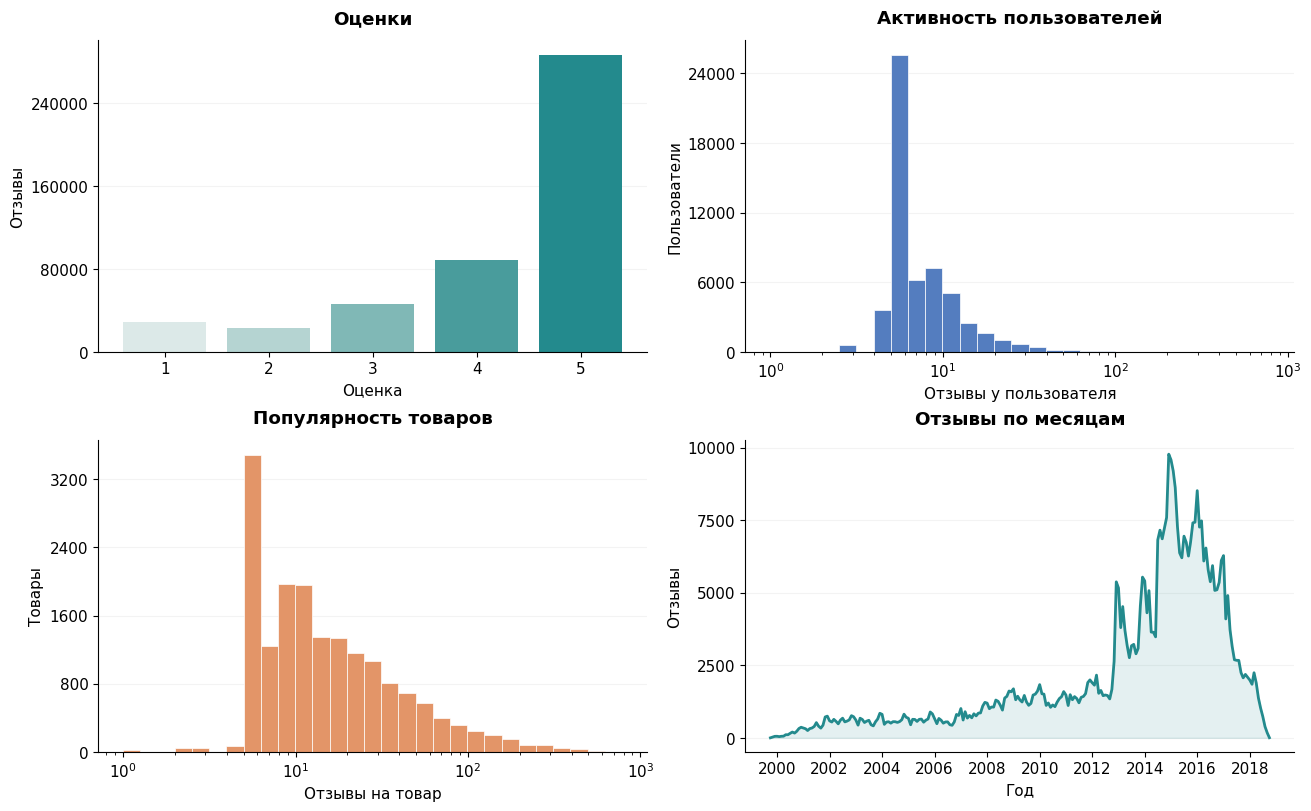

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlepad": 12,
})
teal, blue, coral = "#238A8D", "#547DBF", "#E39568"
fig, axes = plt.subplots(2, 2, figsize=(13, 8), layout="constrained")

ratings = interactions["rating"].value_counts().sort_index()
axes[0, 0].bar(ratings.index, ratings.values, color=["#DCE9E8", "#B5D4D2", "#80B8B6", "#499C9C", teal])
axes[0, 0].set(title="Оценки", xlabel="Оценка", ylabel="Отзывы", xticks=range(1, 6))

for ax, values, title, xlabel, color in [
    (axes[0, 1], user_activity, "Активность пользователей", "Отзывы у пользователя", blue),
    (axes[1, 0], item_popularity, "Популярность товаров", "Отзывы на товар", coral),
]:
    bins = np.geomspace(values.min(), values.max() + 1, 30)
    ax.hist(values, bins=bins, color=color, edgecolor="white", linewidth=0.5)
    ax.set(xscale="log", title=title, xlabel=xlabel, ylabel="Количество")

axes[0, 1].set_ylabel("Пользователи")
axes[1, 0].set_ylabel("Товары")

monthly = interactions.set_index("timestamp").resample("MS").size()
axes[1, 1].plot(monthly.index, monthly.values, color=teal, linewidth=2)
axes[1, 1].fill_between(monthly.index, monthly.values, color=teal, alpha=0.12)
axes[1, 1].set(title="Отзывы по месяцам", xlabel="Год", ylabel="Отзывы")

for ax in axes.flat:
    ax.grid(axis="y", alpha=0.15)
    ax.set_axisbelow(True)
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))
plt.show()

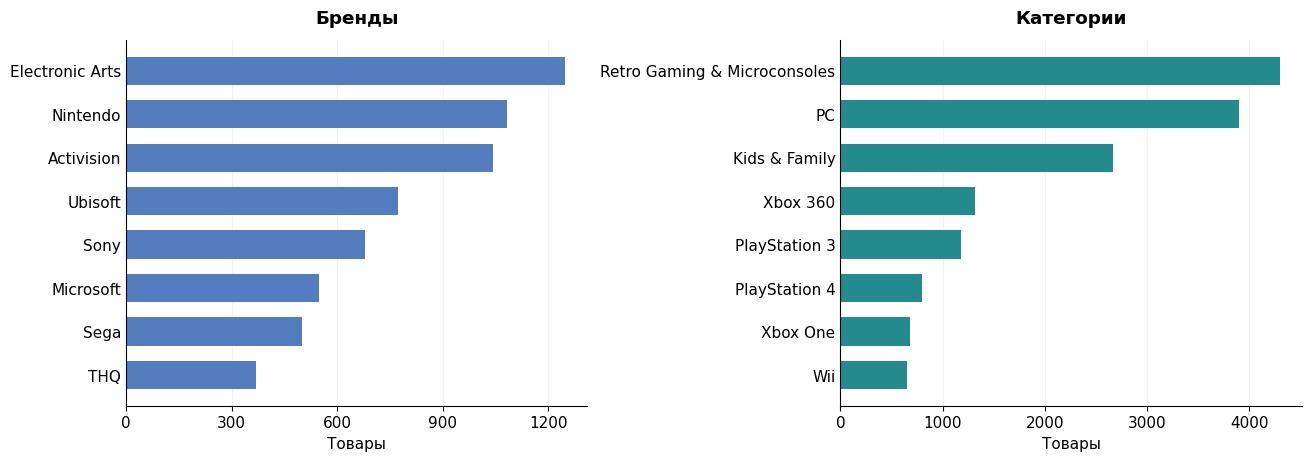

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
brands = items["brand"].replace("", pd.NA).value_counts().head(8).sort_values()
categories = items["category"].str[1].value_counts().head(8).sort_values()

for ax, counts, title, color in [
    (axes[0], brands, "Бренды", blue),
    (axes[1], categories, "Категории", teal),
]:
    ax.barh(counts.index, counts.values, color=color, height=0.65)
    ax.set(title=title, xlabel="Товары")
    ax.grid(axis="x", alpha=0.15)
    ax.set_axisbelow(True)
    ax.tick_params(axis="y", length=0)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))
plt.show()

### Итог подготовки

Чаще всего ставят 5. Медиана — 6 отзывов у пользователя и 12 отзывов на товар.

## 3. Протокол оценки

### Временное разбиение

Делим отзывы по общим датам на 80% train, 10% validation и 10% test.
Внутри каждой части оставляем последнюю оценку пары пользователь–товар.

Модели обучаем на train, гиперпараметры подбираем по validation. Test используем для итогового сравнения.

In [12]:
K, SEED = 10, 42
pair = ["user_id", "item_id"]
ordered = interactions.sort_values("timestamp", kind="stable")
valid_start = ordered["timestamp"].iloc[int(0.8 * len(ordered))]
test_start = ordered["timestamp"].iloc[int(0.9 * len(ordered))]

splits = {
    "train": ordered[ordered["timestamp"] < valid_start],
    "validation": ordered[(ordered["timestamp"] >= valid_start) & (ordered["timestamp"] < test_start)],
    "test": ordered[ordered["timestamp"] >= test_start],
}
split_sizes = {name: len(part) for name, part in splits.items()}
splits = {name: part.drop_duplicates(pair, keep="last").copy() for name, part in splits.items()}
train = splits["train"]

pd.DataFrame([
    {"Период": name, "Начало": part["timestamp"].min().date(),
     "Конец": part["timestamp"].max().date(), "До": split_sizes[name], "После": len(part)}
    for name, part in splits.items()
]).set_index("Период")

,Начало,Конец,До,После
Период,,,,
train,1999-10-14,2016-05-04,378985,378652
validation,2016-05-05,2017-01-14,47465,47433
test,2017-01-15,2018-10-02,47409,47386


### Кандидаты и новые товары

Кандидаты — все товары, встречавшиеся в train. 

В данной реализации будем рекомендовать пользователю только те объекты, на которые он не оставил отзыв в силу специфики рекомендуемых товаров. 

Новый товар выдаем на позиции выдачи $r$ с вероятностью $\frac{r}{1 + ... + 10}$ = $\frac{r}{55}$ случайным 5% пользователей. 

Новым пользователям будем рекомендовать товары случайно, согласно доле отзывов с оценкой 4-5 среди всех отзывов на данный товар за последний месяц обучающей выборки, при условии что отзывов на товар больше 10. 

Рекомендовать товар новому пользователю по количеству отзывов не будем, потому что оно необязательно отражает популярность товара. Возможно, большое количество отзывов свидетельствует о множестве жалоб на товар и не учитывает оценки. 

Оценка за последний месяц используется, чтобы не рекомендовать устаревшие товары. 

В валидационной выборке избавимся от неизвестных ранее товаров и пользователей, чтобы подобрать гиперпараметры. 

В тестовой выборке отложим строки с неизвестных ранее товарами и пользователями. Для них для каждого алгоритма прогнозы будут одинаковы, потому что в моей реализации не зависят от алгоритма.

In [13]:
catalog = np.sort(train["item_id"].unique())
train_users = set(train["user_id"])
cold_report = []

for name in ["validation", "test"]:
    part = splits[name]
    new_users = ~part["user_id"].isin(train_users)
    new_items = ~part["item_id"].isin(catalog)
    cold_report.append({
        "Период": name, "Новый пользователь": (new_users & ~new_items).sum(),
        "Новый товар": (~new_users & new_items).sum(),
        "Оба ID новые": (new_users & new_items).sum(),
        "Осталось": (~new_users & ~new_items).sum(),
    })
    if name == "test":
        test_new_users = part[new_users & ~new_items].copy()
        test_new_items = part[~new_users & new_items].copy()
        test_new_both = part[new_users & new_items].copy()
    splits[name] = part[~new_users & ~new_items].copy()

validation, test = splits["validation"], splits["test"]
test_new_users.to_csv(data_dir / "test_new_users.csv", index=False)
test_new_items.to_csv(data_dir / "test_new_items.csv", index=False)
test_new_both.to_csv(data_dir / "test_new_both.csv", index=False)
pd.DataFrame(cold_report).set_index("Период")

,Новый пользователь,Новый товар,Оба ID новые,Осталось
Период,,,,
validation,14596,7957,1715,23165
test,16667,8091,3435,19193


### Релевантность и момент выдачи

Для validation формируем рекомендации на `valid_start`, для test — на `test_start`.
Эту дату передаём в timeSVD++.

Релевантны товары с последней оценкой 4–5 в проверяемом периоде,
оставшиеся среди кандидатов пользователя. Оцениваем пользователей хотя бы с одним
таким товаром. Разбиения, кандидаты и релевантные ответы одинаковы для всех моделей.
Основная метрика — NDCG@10, дополнительная — Recall@10; усредняем по пользователям.

In [14]:
train_seen = train.groupby("user_id")["item_id"].agg(set).to_dict()
seen_pairs = train[pair].assign(seen=True)

evaluation, target_report = {}, []
for name, heldout, date in [
    ("validation", validation, valid_start), ("test", test, test_start),
]:
    labels = heldout.merge(seen_pairs, on=pair, how="left")
    relevant = labels[(labels["rating"] >= 4) & labels["seen"].isna()]
    targets = relevant.groupby("user_id")["item_id"].agg(set).to_dict()
    evaluation[name] = {"date": date, "seen": train_seen, "targets": targets}
    target_report.append({
        "Период": name, "Известных пар исключено": labels["seen"].notna().sum(),
        "Релевантных пар": len(relevant), "Пользователей оценки": len(targets),
        "Без релевантных товаров": heldout["user_id"].nunique() - len(targets),
    })

def candidate_items(user_id, split):
    seen = evaluation[split]["seen"].get(user_id, set())
    return catalog[~np.isin(catalog, list(seen))]

pd.DataFrame(target_report).set_index("Период")

,Известных пар исключено,Релевантных пар,Пользователей оценки,Без релевантных товаров
Период,,,,
validation,26,18646,8138,1513
test,3,15068,6946,1476


## 4.1. Коллаборативная фильтрация на основе соседей

**Что подбираем:**

- `kind` — user-based или item-based.
- `similarity` — мера сходства пользователей или товаров.
- `n_neighbors` — максимальное число соседей для прогноза.
- `min_common` — минимум общих взаимодействий для расчёта сходства.
- `shrinkage` — насколько уменьшаем доверие к сходству при малом числе общих взаимодействий.

In [15]:
from models.neighborhood import NeighborhoodCF
from models.selection import tune_neighbors
from models.evaluation import evaluate

validation_results, best_params = tune_neighbors(
    train, evaluation["validation"], results_path=data_dir / "cf_validation.csv",
)
validation_results.groupby(["kind", "similarity"], sort=False).head(1).round(4)

user, cosine, min_common=3, shrinkage=10: NDCG@10=0.0030, 8.9 с


user, centered_cosine, min_common=3, shrinkage=10: NDCG@10=0.0014, 8.4 с


user, binary_cosine, min_common=3, shrinkage=10: NDCG@10=0.0024, 8.2 с


user, jaccard, min_common=3, shrinkage=10: NDCG@10=0.0025, 7.9 с


item, cosine, min_common=3, shrinkage=10: NDCG@10=0.0067, 11.7 с


...

item, cosine, min_common=3, shrinkage=50: NDCG@10=0.0068, 11.2 с


item, cosine, min_common=5, shrinkage=0: NDCG@10=0.0045, 10.8 с


item, cosine, min_common=5, shrinkage=10: NDCG@10=0.0047, 10.9 с


item, cosine, min_common=5, shrinkage=50: NDCG@10=0.0048, 10.9 с


,kind,similarity,n_neighbors,min_common,shrinkage,NDCG@10,Recall@10,Пользователи,"Есть рекомендации, %"
0,item,cosine,80,1,50,0.0070,0.0117,8138,71.6638
15,item,jaccard,20,3,10,0.0062,0.0091,8138,40.3662
18,item,binary_cosine,20,3,10,0.0061,0.0092,8138,40.3662
30,item,centered_cosine,40,3,10,0.0045,0.0072,8138,37.5154
36,user,cosine,80,3,10,0.0030,0.0044,8138,16.7117
39,user,jaccard,80,3,10,0.0025,0.0036,8138,10.9363
41,user,binary_cosine,80,3,10,0.0024,0.0036,8138,10.9363
45,user,centered_cosine,40,3,10,0.0014,0.0017,8138,10.3342


In [16]:
print("Выбранные параметры:", best_params)
validation_results.head(10).round(4)

Выбранные параметры: {'kind': 'item', 'similarity': 'cosine', 'n_neighbors': 80, 'min_common': 1, 'shrinkage': 50}


,kind,similarity,n_neighbors,min_common,shrinkage,NDCG@10,Recall@10,Пользователи,"Есть рекомендации, %"
0,item,cosine,80,1,50,0.0070,0.0117,8138,71.6638
1,item,cosine,20,1,50,0.0070,0.0116,8138,71.6638
2,item,cosine,40,1,50,0.0070,0.0117,8138,71.6638
3,item,cosine,40,3,50,0.0068,0.0111,8138,47.3949
4,item,cosine,20,3,50,0.0068,0.0111,8138,47.3949
5,item,cosine,80,3,50,0.0068,0.0111,8138,47.3949
6,item,cosine,40,3,10,0.0067,0.0110,8138,47.3949
7,item,cosine,80,3,10,0.0067,0.0110,8138,47.3949
8,item,cosine,20,3,10,0.0067,0.0110,8138,47.3949
9,item,cosine,20,3,0,0.0066,0.0107,8138,47.3949


## 4.2. Explicit ALS

**Что подбираем:**

- `n_factors` — размерность векторов пользователей и товаров.
- `regularization` — сила L2-штрафа, сдерживающего переобучение.
- `n_epochs` — число проходов с обновлением всех пользовательских и товарных векторов.

In [17]:
from models.als import ExplicitALS
from models.tuning import tune_model

als_grid = [
    {"n_factors": 16, "regularization": 5.0, "n_epochs": 4, "seed": SEED},
    {"n_factors": 32, "regularization": 10.0, "n_epochs": 5, "seed": SEED},
]
best_als, als_results = tune_model(
    ExplicitALS, als_grid, train, evaluation["validation"], k=K,
    results_path=data_dir / "als_validation.csv",
)
als_results.round(5)

ExplicitALS {'n_factors': 16, 'regularization': 5.0, 'n_epochs': 4, 'seed': 42}: NDCG@10=0.00789, 10.3 с


ExplicitALS {'n_factors': 32, 'regularization': 10.0, 'n_epochs': 5, 'seed': 42}: NDCG@10=0.01267, 12.6 с


,parameters,NDCG@10,Recall@10,Пользователи,"Есть рекомендации, %","fit, с","validation, с"
0,"{'n_factors': 32, 'regularization': 10.0, 'n_e...",0.01267,0.02148,8138,100.0,4.65527,7.90871
1,"{'n_factors': 16, 'regularization': 5.0, 'n_ep...",0.00789,0.01324,8138,100.0,2.34118,7.99636


In [18]:
best_als.predict(validation["user_id"].head(), validation["item_id"].head())

array([2.59206808, 3.39684463, 4.45551066, 4.19848805, 3.61506249])

## 4.3. EASE

**Что подбираем:**

- `regularization` — сила L2-штрафа на веса связей между товарами.

In [19]:
from models.ease import EASE

ease_grid = [{"regularization": 50.0}, {"regularization": 200.0}]
best_ease, ease_results = tune_model(
    EASE, ease_grid, train, evaluation["validation"], k=K,
    results_path=data_dir / "ease_validation.csv",
)
ease_results.round(5)

EASE {'regularization': 50.0}: NDCG@10=0.02253, 17.7 с


EASE {'regularization': 200.0}: NDCG@10=0.02279, 17.9 с


,parameters,NDCG@10,Recall@10,Пользователи,"Есть рекомендации, %","fit, с","validation, с"
0,{'regularization': 200.0},0.02279,0.03553,8138,100.0,9.95588,7.9428
1,{'regularization': 50.0},0.02253,0.03564,8138,100.0,9.85933,7.8270


In [20]:
best_ease.predict(validation["user_id"].head(), validation["item_id"].head())

array([ 0.00164652,  0.00311062, -0.00127657, -0.00043474,  0.01349946],
      dtype=float32)

## 4.4. FM с метапризнаками

**Что подбираем:**

- `n_factors` — размерность векторов признаков для их попарных взаимодействий.
- `epochs` — число полных проходов по положительным train-парам.
- `max_features` — максимум слов в TF-IDF; остальные признаки не ограничивает.

In [21]:
from models.fm import FactorizationMachine

fm_grid = [
    {"n_factors": 8, "epochs": 2, "max_features": 128, "random_state": SEED},
    {"n_factors": 16, "epochs": 3, "max_features": 256, "random_state": SEED},
]
best_fm, fm_results = tune_model(
    FactorizationMachine, fm_grid, train, evaluation["validation"], items=items, k=K,
    results_path=data_dir / "fm_validation.csv",
)
fm_results.round(5)

FactorizationMachine {'n_factors': 8, 'epochs': 2, 'max_features': 128, 'random_state': 42}: NDCG@10=0.00428, 12.0 с


FactorizationMachine {'n_factors': 16, 'epochs': 3, 'max_features': 256, 'random_state': 42}: NDCG@10=0.00718, 12.8 с


,parameters,NDCG@10,Recall@10,Пользователи,"Есть рекомендации, %","fit, с","validation, с"
0,"{'n_factors': 16, 'epochs': 3, 'max_features':...",0.00718,0.01238,8138,100.0,4.59265,8.23989
1,"{'n_factors': 8, 'epochs': 2, 'max_features': ...",0.00428,0.00806,8138,100.0,3.86723,8.17301


In [22]:
best_fm.predict(validation["user_id"].head(), validation["item_id"].head())

array([2.7492294, 1.4702716, 4.4882736, 1.9488426, 3.8838367],
      dtype=float32)

## 4.5. timeSVD++

**Что подбираем:**

- `n_factors` — размерность скрытых векторов пользователей, товаров и истории.
- `n_epochs` — число полных проходов по train-отзывам.

In [23]:
from models.timesvd import TimeSVDPlusPlus

timesvd_grid = [
    {"n_factors": 8, "n_epochs": 2, "random_state": SEED},
    {"n_factors": 16, "n_epochs": 4, "random_state": SEED},
]
best_timesvd, timesvd_results = tune_model(
    TimeSVDPlusPlus, timesvd_grid, train, evaluation["validation"], k=K,
    results_path=data_dir / "timesvd_validation.csv",
)
timesvd_results.round(5)

TimeSVDPlusPlus {'n_factors': 8, 'n_epochs': 2, 'random_state': 42}: NDCG@10=0.00210, 9.7 с


TimeSVDPlusPlus {'n_factors': 16, 'n_epochs': 4, 'random_state': 42}: NDCG@10=0.00152, 10.4 с


,parameters,NDCG@10,Recall@10,Пользователи,"Есть рекомендации, %","fit, с","validation, с"
0,"{'n_factors': 8, 'n_epochs': 2, 'random_state'...",0.00210,0.00377,8138,100.0,1.67167,8.03656
1,"{'n_factors': 16, 'n_epochs': 4, 'random_state...",0.00152,0.00256,8138,100.0,2.27128,8.12722


In [24]:
best_timesvd.predict(
    validation["user_id"].head(), validation["item_id"].head(), date=valid_start,
)

array([4.449641 , 4.329964 , 4.4560847, 4.742884 , 4.7053723],
      dtype=float32)

### Выбранные настройки на validation

По одной лучшей настройке для каждой новой модели.

In [25]:
model_validation = pd.DataFrame([
    {"Модель": name, **results.iloc[0].to_dict()}
    for name, results in [("Explicit ALS", als_results), ("EASE", ease_results),
                          ("FM", fm_results), ("timeSVD++", timesvd_results)]
]).set_index("Модель")
model_validation.to_csv(data_dir / "model_validation.csv")
with pd.option_context("display.max_colwidth", None):
    display(model_validation[["parameters", "NDCG@10", "Recall@10", "fit, с", "validation, с"]].round(5))

,parameters,NDCG@10,Recall@10,"fit, с","validation, с"
Модель,,,,,
Explicit ALS,"{'n_factors': 32, 'regularization': 10.0, 'n_epochs': 5, 'seed': 42}",0.01267,0.02148,4.65527,7.90871
EASE,{'regularization': 200.0},0.02279,0.03553,9.95588,7.94280
FM,"{'n_factors': 16, 'epochs': 3, 'max_features': 256, 'random_state': 42}",0.00718,0.01238,4.59265,8.23989
timeSVD++,"{'n_factors': 8, 'n_epochs': 2, 'random_state': 42}",0.00210,0.00377,1.67167,8.03656


## 5. Сравнение на test

**NDCG@10** учитывает попадания и их позиции: релевантный товар в начале выдачи ценнее.
**Recall@10** показывает, какую долю релевантных товаров пользователя удалось включить в выдачу.
Вместе метрики оценивают порядок и полноту рекомендаций; усредняем по пользователям.

Используем настройки, выбранные на валидации, и посчитаем метрики на тесту.

In [26]:
best_cf = NeighborhoodCF(**best_params).fit(train)
runs = [
    ("CF", "cf", best_cf, best_params),
    ("ALS", "als", best_als, als_results.iloc[0]["parameters"]),
    ("EASE", "ease", best_ease, ease_results.iloc[0]["parameters"]),
    ("FM", "fm", best_fm, fm_results.iloc[0]["parameters"]),
    ("timeSVD++", "timesvd", best_timesvd, timesvd_results.iloc[0]["parameters"]),
]
test_rows = []
for name, filename, model, parameters in runs:
    metrics, recommendations = evaluate(
        model, evaluation["test"]["targets"], evaluation["test"]["seen"],
        k=K, date=test_start, return_recommendations=True,
    )
    test_rows.append({"Модель": name, "parameters": parameters, **metrics})
    recommendations.to_csv(data_dir / f"{filename}_test_recommendations.csv", index=False)
    print(f"{name}: NDCG@10={metrics['NDCG@10']:.5f}, Recall@10={metrics['Recall@10']:.5f}")

test_results = pd.DataFrame(test_rows).set_index("Модель").sort_values("NDCG@10", ascending=False)
test_results.to_csv(data_dir / "test_results.csv")
with pd.option_context("display.max_colwidth", None):
    display(test_results.round(5))

CF: NDCG@10=0.00447, Recall@10=0.00771


ALS: NDCG@10=0.01277, Recall@10=0.02092


EASE: NDCG@10=0.01561, Recall@10=0.02399


FM: NDCG@10=0.00580, Recall@10=0.00997


timeSVD++: NDCG@10=0.00155, Recall@10=0.00285


,parameters,NDCG@10,Recall@10,Пользователи,"Есть рекомендации, %"
Модель,,,,,
EASE,{'regularization': 200.0},0.01561,0.02399,6946,100.00000
ALS,"{'n_factors': 32, 'regularization': 10.0, 'n_epochs': 5, 'seed': 42}",0.01277,0.02092,6946,100.00000
FM,"{'n_factors': 16, 'epochs': 3, 'max_features': 256, 'random_state': 42}",0.00580,0.00997,6946,100.00000
CF,"{'kind': 'item', 'similarity': 'cosine', 'n_neighbors': 80, 'min_common': 1, 'shrinkage': 50}",0.00447,0.00771,6946,69.32047
timeSVD++,"{'n_factors': 8, 'n_epochs': 2, 'random_state': 42}",0.00155,0.00285,6946,100.00000


### Влияние метаданных

Сравниваем FM с выбранными настройками и её вариант только с user/item ID.
Число факторов, эпохи, регуляризация, шаг обучения и зерно одинаковы.
Отличается только наличие метаданных; по test настройки не меняем.

In [27]:
fm_ids = FactorizationMachine(
    **fm_results.iloc[0]["parameters"], use_metadata=False,
).fit(train, items)
ids_metrics = evaluate(
    fm_ids, evaluation["test"]["targets"], evaluation["test"]["seen"], k=K, date=test_start,
)
metric_columns = ["NDCG@10", "Recall@10"]
metadata_results = pd.DataFrame([
    {"Признаки": "Только ID", **{metric: ids_metrics[metric] for metric in metric_columns}},
    {"Признаки": "ID + метаданные", **test_results.loc["FM", metric_columns].to_dict()},
]).set_index("Признаки")
metadata_results.to_csv(data_dir / "fm_metadata_test.csv")
metadata_results.round(5)

,NDCG@10,Recall@10
Признаки,,
Только ID,0.00915,0.01573
ID + метаданные,0.00580,0.00997


## 6. Выводы

- **Лучший результат — EASE:** NDCG@10 = 0.01561, Recall@10 = 0.02399.
  ALS на втором месте; преимущество EASE по NDCG — 22.2%.
  Выбранные на validation настройки всех моделей приведены в общей таблице.
- **Метаданные не улучшили FM при этих настройках:** NDCG снизился с 0.00915
  у варианта только с ID до 0.00580 (36.6%), Recall — с 0.01573 до 0.00997.
  Вывод относится к текущей обработке признаков и короткому обучению.
- **У CF ограничена выдача:** у 30.68% пользователей не нашлось допустимых рекомендаций.
  Их нулевые результаты включены в метрики.
- **timeSVD++ оказался последним:** NDCG@10 = 0.00155.
  Проверены короткие запуски; сходимость не оценивали, поэтому вывод о предельном качестве делать рано.
- **Ограничения:** сравниваем только известные ID и пользователей с релевантными ответами.
  Настройки проверялись небольшим поиском и с одним зерном, без оценки разброса.
  Метаданные — снимок без истории изменений. Результаты показывают качество одной фиксированной выдачи,
  без обновления модели и истории внутри test-периода.